<a href="https://colab.research.google.com/github/Nandhish130/DL-UNIT-TEST-2/blob/main/Household_Electricity_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
filename = "household_power_consumption.csv"

df = pd.read_csv(
    filename,
    na_values=["?"],
    low_memory=False
)

if "index" in df.columns:
    df = df.drop(columns=["index"])

print("Dataset loaded successfully!")
display(df.head())

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing values:")
print(df.isnull().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'household_power_consumption.csv'

In [5]:
import os

print(os.listdir("/content"))

['.config', 'archive.zip', 'sample_data']


In [6]:
import zipfile
import os

with zipfile.ZipFile("/content/archive.zip", "r") as zip_ref:
    zip_ref.extractall("/content")

print(os.listdir("/content"))

['.config', 'household_power_consumption.txt', 'archive.zip', 'sample_data']


In [7]:

import pandas as pd
import os

filename = "/content/household_power_consumption.txt"

df = pd.read_csv(
    filename,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [8]:
filename = "/content/household_power_consumption.csv"

df = pd.read_csv(
    filename,
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/household_power_consumption.csv'

In [9]:
import os

print(os.listdir("/content"))

['.config', 'household_power_consumption.txt', 'archive.zip', 'sample_data']


In [10]:
import zipfile
import os

with zipfile.ZipFile("/content/archive.zip", "r") as z:
    z.extractall("/content")

for root, dirs, files in os.walk("/content"):
    for file in files:
        print(os.path.join(root, file))

/content/household_power_consumption.txt
/content/archive.zip
/content/.config/active_config
/content/.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
/content/.config/config_sentinel
/content/.config/.last_update_check.json
/content/.config/default_configs.db
/content/.config/.last_opt_in_prompt.yaml
/content/.config/gce
/content/.config/.last_survey_prompt.yaml
/content/.config/configurations/config_default
/content/.config/logs/2026.10.02/13.50.15.366402.log
/content/.config/logs/2026.10.02/13.50.08.874802.log
/content/.config/logs/2026.10.02/13.50.21.555054.log
/content/.config/logs/2026.10.02/13.49.46.128557.log
/content/.config/logs/2026.10.02/13.50.14.261149.log
/content/.config/logs/2026.10.02/13.50.21.004336.log
/content/sample_data/anscombe.json
/content/sample_data/README.md
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_test.csv


In [11]:
filename = "/content/household_power_consumption.txt"

df = pd.read_csv(
    filename,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [12]:
df["Datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    dayfirst=True,
    errors="coerce"
)

df = df.dropna(subset=["Datetime"])
df = df.sort_values("Datetime")
df = df.drop_duplicates(subset=["Datetime"])
df = df.set_index("Datetime")

features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

df[features] = df[features].apply(
    pd.to_numeric, errors="coerce"
)

df = df[features].iloc[:10000].copy()

df = df.interpolate(method="time").ffill().bfill()

print("Data cleaning completed!")
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

display(df.head())

Data cleaning completed!
Dataset shape: (10000, 7)

Missing values:
Global_active_power      0
Global_reactive_power    0
Voltage                  0
Global_intensity         0
Sub_metering_1           0
Sub_metering_2           0
Sub_metering_3           0
dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
Datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [13]:
from sklearn.preprocessing import MinMaxScaler

n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

scaler = MinMaxScaler()
scaler.fit(df.iloc[:train_end])

scaled_data = scaler.transform(df)

print("Normalization completed!")
print("Data shape:", scaled_data.shape)

Normalization completed!
Data shape: (10000, 7)


In [14]:
sequence_length = 60
target_index = 0

def create_sequences(data, start, end):
    X, y = [], []

    for i in range(start, end):
        X.append(data[i-sequence_length:i])
        y.append(data[i, target_index])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(
    scaled_data, sequence_length, train_end
)

X_val, y_val = create_sequences(
    scaled_data, train_end, val_end
)

X_test, y_test = create_sequences(
    scaled_data, val_end, n
)

print("Sequences created successfully!")
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

Sequences created successfully!
X_train: (6940, 60, 7)
X_val: (1500, 60, 7)
X_test: (1500, 60, 7)


In [15]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(60, 7)),
    Dropout(0.2),
    LSTM(32),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 60, 64)         │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,393 (122.63 KB)

 Trainable params: 31,393 (122.63 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

print("Model training completed!")

Epoch 1/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 12s 72ms/step - loss: 0.0238 - mae: 0.1081 - val_loss: 0.0064 - val_mae: 0.0503
Epoch 2/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 67ms/step - loss: 0.0086 - mae: 0.0626 - val_loss: 0.0050 - val_mae: 0.0400
Epoch 3/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 11s 76ms/step - loss: 0.0069 - mae: 0.0554 - val_loss: 0.0044 - val_mae: 0.0356
Epoch 4/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 81ms/step - loss: 0.0065 - mae: 0.0527 - val_loss: 0.0039 - val_mae: 0.0348
Epoch 5/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 69ms/step - loss: 0.0065 - mae: 0.0538 - val_loss: 0.0036 - val_mae: 0.0332
Epoch 6/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 10s 69ms/step - loss: 0.0053 - mae: 0.0457 - val_loss: 0.0032 - val_mae: 0.0274
Epoch 7/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 9s 80ms/step - loss: 0.0051 - mae: 0.0453 - val_loss: 0.0032 - val_mae: 0.0261
Epoch 8/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 8s 78ms/step - loss: 0.0050 - mae: 0.0442 - val_loss: 0.0031 - val_mae: 0.0267
Epoch 9/20
109/109 ━━━━━━━━━━━━━━━━━━━━ 8s 70

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

predictions_scaled = model.predict(X_test)

target_min = scaler.data_min_[target_index]
target_max = scaler.data_max_[target_index]
target_range = target_max - target_min

actual = y_test * target_range + target_min
predicted = predictions_scaled.flatten() * target_range + target_min

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("MAE:", mae)
print("RMSE:", rmse)

47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step
MAE: 0.6610303142220081
RMSE: 0.8160510129822985


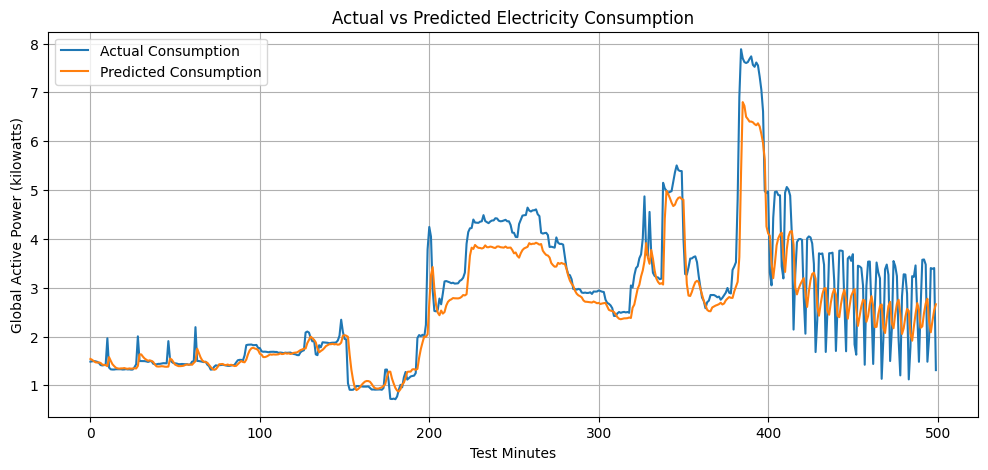

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(actual[:500], label="Actual Consumption")
plt.plot(predicted[:500], label="Predicted Consumption")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test Minutes")
plt.ylabel("Global Active Power (kilowatts)")
plt.legend()
plt.grid(True)
plt.show()

In [19]:
from google.colab import files

model.save("household_electricity_lstm.keras")

print("Model saved successfully!")

files.download("household_electricity_lstm.keras")

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>